# 自然语言处理作业一：NYT 新闻文本分类

本 Notebook 完整实现两种 Bag of Words、三种 100 维平均词向量和 BERT 微调，共六组实验。所有分类器使用同一份 NYT 训练、验证、测试划分；测试集只在模型确定后用于最终评价。

**输入**：与本 Notebook 同目录的 `nyt.csv`（`text,label`）和 `ag.csv`（`text`）。GloVe 使用作业指定的 `glove.6B.100d.txt`，本 Notebook 可从 Stanford 压缩包自动提取。BERT 使用 `google-bert/bert-base-uncased`，首次运行需访问 Hugging Face。

**运行前**：建议使用有 GPU 的 Python 3.10+ 环境；安装 `numpy pandas scipy scikit-learn gensim matplotlib torch transformers`。例如在终端执行：

```bash
python -m pip install numpy pandas scipy scikit-learn gensim matplotlib torch transformers ipykernel
```

从头依次运行所有单元。GloVe 下载量约 800 MB，BERT 微调需要较长时间和数 GB 内存/显存；无网络时可先将 `glove.6B.100d.txt` 放入 `assets/`，并预先缓存 BERT 模型。代码不会伪造或预填实验结果。

## 1. 环境与参数

In [1]:
from __future__ import annotations

import csv
import os
import random
import re
import shutil
import urllib.request
import zipfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from gensim.models import Word2Vec
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

SEED = 42
ROOT = Path.cwd()
NYT_PATH = ROOT / "nyt.csv"
AG_PATH = ROOT / "ag.csv"
ASSET_DIR = ROOT / "assets"
ARTIFACT_DIR = ROOT / "artifacts"
ASSET_DIR.mkdir(exist_ok=True)
ARTIFACT_DIR.mkdir(exist_ok=True)

GLOVE_PATH = ASSET_DIR / "glove.6B.100d.txt"
GLOVE_ZIP_PATH = ASSET_DIR / "glove.6B.zip"
GLOVE_URL = "https://nlp.stanford.edu/data/glove.6B.zip"
BERT_NAME = "google-bert/bert-base-uncased"
MAX_LENGTH = 64
BERT_EPOCHS = 3
WORD_VECTOR_SIZE = 100

random.seed(SEED)
np.random.seed(SEED)

for path in (NYT_PATH, AG_PATH):
    if not path.is_file():
        raise FileNotFoundError(f"缺少输入文件：{path}")

print("数据目录：", ROOT)
print("随机种子：", SEED)

数据目录： /home/HW1
随机种子： 42


## 2. 读取数据并固定 NYT 划分

In [2]:
nyt = pd.read_csv(NYT_PATH, encoding="utf-8-sig")
ag = pd.read_csv(AG_PATH, encoding="utf-8-sig", usecols=["text"])
if not {"text", "label"}.issubset(nyt.columns):
    raise ValueError("nyt.csv 必须包含 text 和 label 两列")
if "text" not in ag.columns:
    raise ValueError("ag.csv 必须包含 text 列")

missing_nyt = nyt[["text", "label"]].isna().any(axis=1) | nyt["text"].astype(str).str.strip().eq("") | nyt["label"].astype(str).str.strip().eq("")
missing_ag = ag["text"].isna() | ag["text"].astype(str).str.strip().eq("")
print(f"NYT 原始 {len(nyt):,} 行，无效 {int(missing_nyt.sum()):,} 行")
print(f"AG 原始 {len(ag):,} 行，无效 {int(missing_ag.sum()):,} 行")
nyt = nyt.loc[~missing_nyt, ["text", "label"]].reset_index(drop=True).copy()
ag = ag.loc[~missing_ag, ["text"]].reset_index(drop=True).copy()
nyt["text"] = nyt["text"].astype(str)
nyt["label"] = nyt["label"].astype(str)
ag["text"] = ag["text"].astype(str)

print("NYT 类别分布：")
display(nyt["label"].value_counts().to_frame("count"))
print("NYT 重复文本条数：", int(nyt["text"].duplicated().sum()))
print("AG 文本条数：", len(ag))

NYT 原始 11,519 行，无效 0 行
AG 原始 90,000 行，无效 0 行
NYT 类别分布：


,count
label,
sports,8639
politics,1451
business,1429


NYT 重复文本条数： 72
AG 文本条数： 90000


### 划分说明

按类别分层、随机打乱后以 80%/10%/10% 划分；`random_state=42` 固定。分层是为了让少数类在三组中都有代表性。后续所有方法都使用下面的索引。Word2Vec 在 NYT 上只使用训练集文本，避免从验证集或测试集学习词向量。

原始 NYT 可能含完全相同的文本；这里按作业要求划分全部有效行，不做去重。重复文本跨集合出现会让指标略显乐观，报告中应注明。

In [3]:
all_idx = np.arange(len(nyt))
train_idx, holdout_idx = train_test_split(
    all_idx, test_size=0.20, random_state=SEED, shuffle=True,
    stratify=nyt["label"].to_numpy(),
)
val_idx, test_idx = train_test_split(
    holdout_idx, test_size=0.50, random_state=SEED, shuffle=True,
    stratify=nyt.iloc[holdout_idx]["label"].to_numpy(),
)
assert len(set(train_idx) & set(val_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(val_idx) & set(test_idx)) == 0
assert len(train_idx) + len(val_idx) + len(test_idx) == len(nyt)

train_text = nyt.iloc[train_idx]["text"].tolist()
val_text = nyt.iloc[val_idx]["text"].tolist()
test_text = nyt.iloc[test_idx]["text"].tolist()
label_encoder = LabelEncoder().fit(nyt.iloc[train_idx]["label"])
y_train = label_encoder.transform(nyt.iloc[train_idx]["label"])
y_val = label_encoder.transform(nyt.iloc[val_idx]["label"])
y_test = label_encoder.transform(nyt.iloc[test_idx]["label"])
class_names = label_encoder.classes_.tolist()

split_summary = pd.DataFrame({
    "split": ["Train", "Validation", "Test"],
    "samples": [len(train_idx), len(val_idx), len(test_idx)],
    "fraction": [len(train_idx)/len(nyt), len(val_idx)/len(nyt), len(test_idx)/len(nyt)],
})
display(split_summary)
print("类别顺序：", class_names)
print("各集合类别计数：")
display(pd.DataFrame({
    "Train": pd.Series(y_train).value_counts().sort_index().to_numpy(),
    "Validation": pd.Series(y_val).value_counts().sort_index().to_numpy(),
    "Test": pd.Series(y_test).value_counts().sort_index().to_numpy(),
}, index=class_names))

,split,samples,fraction
0,Train,9215,0.799983
1,Validation,1152,0.100009
2,Test,1152,0.100009


类别顺序： ['business', 'politics', 'sports']
各集合类别计数：


,Train,Validation,Test
business,1143,143,143
politics,1161,145,145
sports,6911,864,864


## 3. 统一评价函数

In [4]:
results = []

def evaluate_predictions(name, y_true, y_pred, split="Test", record=True):
    row = {
        "Method": name,
        "Split": split,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro-F1": f1_score(y_true, y_pred, average="macro", labels=np.arange(len(class_names)), zero_division=0),
    }
    if record:
        results.append(row)
    print(f"{name} | {split} | Accuracy={row['Accuracy']:.4f} | Macro-F1={row['Macro-F1']:.4f}")
    print(classification_report(y_true, y_pred, labels=np.arange(len(class_names)), target_names=class_names, zero_division=0))
    return row

def fit_logistic_regression(X_train, y_train, X_val, y_val):
    # 仅用验证集选择正则化强度，返回重新拟合后的模型。
    candidates = [0.1, 1.0, 10.0]
    scores = []
    for c_value in candidates:
        model = LogisticRegression(C=c_value, max_iter=1000, solver="lbfgs", random_state=SEED)
        model.fit(X_train, y_train)
        score = f1_score(y_val, model.predict(X_val), average="macro", zero_division=0)
        scores.append(score)
        print(f"C={c_value:g}: Validation Macro-F1={score:.4f}")
    best_c = candidates[int(np.argmax(scores))]
    print("选择 C=", best_c)
    final_model = LogisticRegression(C=best_c, max_iter=1000, solver="lbfgs", random_state=SEED)
    final_model.fit(X_train, y_train)
    return final_model, best_c

## 4. Task 1：Binary Bag of Words 与 Word Frequency

词表只从 NYT 训练集建立。两种表示共用相同词表，Binary 把非零词频设为 1；Word Frequency 保留原始词频。

In [5]:
vectorizer = CountVectorizer(lowercase=True, token_pattern=r"(?u)\b\w+\b", dtype=np.int32)
X_train_count = vectorizer.fit_transform(train_text)
X_val_count = vectorizer.transform(val_text)
X_test_count = vectorizer.transform(test_text)
print("词表大小：", len(vectorizer.vocabulary_))
print("训练矩阵：", X_train_count.shape, "非零元素：", X_train_count.nnz)

X_train_binary = X_train_count.copy()
X_val_binary = X_val_count.copy()
X_test_binary = X_test_count.copy()
for matrix in (X_train_binary, X_val_binary, X_test_binary):
    matrix.data[:] = 1

词表大小： 61021
训练矩阵： (9215, 61021) 非零元素： 2901622


In [6]:
bow_binary_model, binary_c = fit_logistic_regression(
    X_train_binary, y_train, X_val_binary, y_val
)
binary_pred = bow_binary_model.predict(X_test_binary)
evaluate_predictions("Binary Bag of Words + LR", y_test, binary_pred)

C=0.1: Validation Macro-F1=0.9595
C=1: Validation Macro-F1=0.9551
C=10: Validation Macro-F1=0.9574
选择 C= 0.1
Binary Bag of Words + LR | Test | Accuracy=0.9878 | Macro-F1=0.9704
              precision    recall  f1-score   support

    business       0.96      0.94      0.95       143
    politics       0.95      0.97      0.96       145
      sports       1.00      1.00      1.00       864

    accuracy                           0.99      1152
   macro avg       0.97      0.97      0.97      1152
weighted avg       0.99      0.99      0.99      1152



{'Method': 'Binary Bag of Words + LR',
 'Split': 'Test',
 'Accuracy': 0.9878472222222222,
 'Macro-F1': 0.9703589469382573}

In [7]:
bow_count_model, count_c = fit_logistic_regression(
    X_train_count, y_train, X_val_count, y_val
)
count_pred = bow_count_model.predict(X_test_count)
evaluate_predictions("Word Frequency + LR", y_test, count_pred)

C=0.1: Validation Macro-F1=0.9613
C=1: Validation Macro-F1=0.9626
C=10: Validation Macro-F1=0.9564
选择 C= 1.0
Word Frequency + LR | Test | Accuracy=0.9896 | Macro-F1=0.9743
              precision    recall  f1-score   support

    business       0.93      0.99      0.96       143
    politics       0.99      0.94      0.96       145
      sports       1.00      1.00      1.00       864

    accuracy                           0.99      1152
   macro avg       0.97      0.98      0.97      1152
weighted avg       0.99      0.99      0.99      1152



{'Method': 'Word Frequency + LR',
 'Split': 'Test',
 'Accuracy': 0.9895833333333334,
 'Macro-F1': 0.9742712191040632}

## 5. Task 2：100 维平均词向量

统一将文本小写后按 Unicode 词边界分词；仅平均词表中存在的词向量，重复出现的词按出现次数参与平均。没有任何有效词的文档用全零向量表示，并报告覆盖率。三组词向量各自训练或加载，文档分类器都是 Logistic Regression。

In [8]:
TOKEN_RE = re.compile(r"(?u)\b\w+\b")

def tokenize(text):
    return TOKEN_RE.findall(text.lower())

def mean_document_vectors(texts, keyed_vectors, dimension=WORD_VECTOR_SIZE):
    vectors = np.zeros((len(texts), dimension), dtype=np.float32)
    matched_tokens = 0
    total_tokens = 0
    empty_docs = 0
    for row, text in enumerate(texts):
        tokens = tokenize(text)
        total_tokens += len(tokens)
        present = [keyed_vectors[word] for word in tokens if word in keyed_vectors]
        matched_tokens += len(present)
        if present:
            vectors[row] = np.mean(present, axis=0)
        else:
            empty_docs += 1
    coverage = matched_tokens / total_tokens if total_tokens else 0.0
    print(f"{len(texts):,} 文档，token 覆盖率={coverage:.2%}，零向量文档={empty_docs}")
    return vectors

def run_embedding_experiment(name, keyed_vectors):
    X_tr = mean_document_vectors(train_text, keyed_vectors)
    X_va = mean_document_vectors(val_text, keyed_vectors)
    X_te = mean_document_vectors(test_text, keyed_vectors)
    model, selected_c = fit_logistic_regression(X_tr, y_train, X_va, y_val)
    predictions = model.predict(X_te)
    evaluate_predictions(name, y_test, predictions)
    return model, selected_c, predictions

### 5.1 预训练 GloVe glove.6B.100d

In [9]:
def ensure_glove_100d():
    if GLOVE_PATH.is_file():
        return GLOVE_PATH
    if not GLOVE_ZIP_PATH.is_file():
        print("正在下载 Stanford glove.6B.zip；首次下载约 800 MB……")
        try:
            with urllib.request.urlopen(GLOVE_URL, timeout=120) as response, GLOVE_ZIP_PATH.open("wb") as output:
                shutil.copyfileobj(response, output)
        except Exception as exc:
            GLOVE_ZIP_PATH.unlink(missing_ok=True)
            raise RuntimeError(
                f"GloVe 下载失败。可手动下载 {GLOVE_URL}，并把 glove.6B.100d.txt 放入 {ASSET_DIR}"
            ) from exc
    print("正在从压缩包提取 100 维词向量……")
    with zipfile.ZipFile(GLOVE_ZIP_PATH) as archive:
        with archive.open("glove.6B.100d.txt") as source, GLOVE_PATH.open("wb") as target:
            shutil.copyfileobj(source, target)
    return GLOVE_PATH

def load_needed_glove(path, texts):
    required_words = set()
    for text in texts:
        required_words.update(tokenize(text))
    vectors = {}
    with path.open("r", encoding="utf-8") as file:
        for line in file:
            word, *values = line.rstrip().split(" ")
            if word in required_words:
                if len(values) != WORD_VECTOR_SIZE:
                    raise ValueError(f"GloVe 向量维度异常：{word}")
                vectors[word] = np.asarray(values, dtype=np.float32)
    print(f"NYT 词表 {len(required_words):,} 词；找到 GloVe 向量 {len(vectors):,} 个")
    return vectors

glove_vectors = load_needed_glove(ensure_glove_100d(), train_text + val_text + test_text)
glove_model, glove_c, glove_pred = run_embedding_experiment("GloVe 100d mean + LR", glove_vectors)

NYT 词表 65,981 词；找到 GloVe 向量 59,707 个
9,215 文档，token 覆盖率=99.78%，零向量文档=0
1,152 文档，token 覆盖率=99.77%，零向量文档=0
1,152 文档，token 覆盖率=99.79%，零向量文档=0
C=0.1: Validation Macro-F1=0.9226
C=1: Validation Macro-F1=0.9500
C=10: Validation Macro-F1=0.9522
选择 C= 10.0
GloVe 100d mean + LR | Test | Accuracy=0.9852 | Macro-F1=0.9646
              precision    recall  f1-score   support

    business       0.93      0.97      0.95       143
    politics       0.96      0.94      0.95       145
      sports       1.00      1.00      1.00       864

    accuracy                           0.99      1152
   macro avg       0.96      0.97      0.96      1152
weighted avg       0.99      0.99      0.99      1152



### 5.2 在 AG News 文本上训练 Word2Vec

In [10]:
class AGTokenCorpus:
    # 可重复遍历，避免把 AG 的全部分词结果常驻内存。
    def __iter__(self):
        with AG_PATH.open("r", encoding="utf-8-sig", newline="") as file:
            for row in csv.DictReader(file):
                if row.get("text") and row["text"].strip():
                    tokens = tokenize(row["text"])
                    if tokens:
                        yield tokens

ag_word2vec = Word2Vec(
    sentences=AGTokenCorpus(), vector_size=WORD_VECTOR_SIZE, window=5,
    min_count=2, workers=1, sg=1, epochs=5, seed=SEED,
)
print("AG Word2Vec 词表大小：", len(ag_word2vec.wv))
ag_model, ag_c, ag_pred = run_embedding_experiment("AG Word2Vec 100d mean + LR", ag_word2vec.wv)

AG Word2Vec 词表大小： 37062
9,215 文档，token 覆盖率=97.34%，零向量文档=0
1,152 文档，token 覆盖率=97.26%，零向量文档=0
1,152 文档，token 覆盖率=97.33%，零向量文档=0
C=0.1: Validation Macro-F1=0.8844
C=1: Validation Macro-F1=0.9228
C=10: Validation Macro-F1=0.9406
选择 C= 10.0
AG Word2Vec 100d mean + LR | Test | Accuracy=0.9826 | Macro-F1=0.9567
              precision    recall  f1-score   support

    business       0.92      0.95      0.93       143
    politics       0.95      0.92      0.94       145
      sports       1.00      1.00      1.00       864

    accuracy                           0.98      1152
   macro avg       0.96      0.96      0.96      1152
weighted avg       0.98      0.98      0.98      1152



### 5.3 仅在 NYT 训练集文本上训练 Word2Vec

In [11]:
class NYTTrainTokenCorpus:
    def __iter__(self):
        for text in train_text:
            tokens = tokenize(text)
            if tokens:
                yield tokens

nyt_word2vec = Word2Vec(
    sentences=NYTTrainTokenCorpus(), vector_size=WORD_VECTOR_SIZE, window=5,
    min_count=2, workers=1, sg=1, epochs=5, seed=SEED,
)
print("NYT Train Word2Vec 词表大小：", len(nyt_word2vec.wv))
nyt_w2v_model, nyt_w2v_c, nyt_w2v_pred = run_embedding_experiment(
    "NYT Word2Vec 100d mean + LR", nyt_word2vec.wv
)

NYT Train Word2Vec 词表大小： 43434
9,215 文档，token 覆盖率=99.71%，零向量文档=0
1,152 文档，token 覆盖率=99.23%，零向量文档=0
1,152 文档，token 覆盖率=99.29%，零向量文档=0
C=0.1: Validation Macro-F1=0.8966
C=1: Validation Macro-F1=0.9304
C=10: Validation Macro-F1=0.9524
选择 C= 10.0
NYT Word2Vec 100d mean + LR | Test | Accuracy=0.9861 | Macro-F1=0.9658
              precision    recall  f1-score   support

    business       0.94      0.95      0.95       143
    politics       0.96      0.94      0.95       145
      sports       1.00      1.00      1.00       864

    accuracy                           0.99      1152
   macro avg       0.97      0.96      0.97      1152
weighted avg       0.99      0.99      0.99      1152



## 6. Task 3：BERT-base-uncased 微调

使用 `google-bert/bert-base-uncased`，`max_length=64`，完整训练 **3 epochs**。每轮验证集 Macro-F1 用于选择最佳 checkpoint；最终只对最佳 checkpoint 计算一次测试指标。默认 batch size 16；显存不足可降低 batch size，训练轮数和最大长度保持不变。

**耗时与进度**：先检查下方实际设备。若显示 `cpu`，BERT 全参数微调可能每轮耗时数十分钟；安装 CUDA 版 PyTorch 也需要运行环境提供可用 GPU 才能加速。CPU 线程默认设为 2，可调整 `BERT_CPU_THREADS` 后重跑本节比较速度。训练显示首批前向、反向和参数更新耗时，以及每轮的逐批进度、loss 和预计剩余时间；验证也显示进度。使用文本进度条，无需安装 ipywidgets。

**中断后**：`KeyboardInterrupt` 表示执行被中断。重新运行训练单元会重新加载预训练模型、从第 1 轮开始；只有完成验证且分数更好的整轮模型才保存到最佳 checkpoint。修改本节后，先运行设备/数据单元，再运行训练单元；同一 kernel 中此前已完成的词袋和词向量实验无需重跑。


In [12]:
import sys
from time import perf_counter

import torch
from tqdm.std import tqdm
from torch.utils.data import DataLoader, Dataset
from transformers import AutoModelForSequenceClassification, AutoTokenizer

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Python：", sys.executable)
print("PyTorch：", torch.__version__, "CUDA 构建：", torch.version.cuda)
print("CUDA 可用：", torch.cuda.is_available(), "设备：", device)
if device.type == "cpu":
    available_cpus = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else (os.cpu_count() or 1)
    BERT_CPU_THREADS = min(2, available_cpus)
    torch.set_num_threads(BERT_CPU_THREADS)
    print(f"CPU 计算线程：{torch.get_num_threads()}；BERT 全参数训练较慢，请查看逐批进度。")
else:
    print("GPU：", torch.cuda.get_device_name(device))

bert_tokenizer = AutoTokenizer.from_pretrained(BERT_NAME, use_fast=True)

class NewsDataset(Dataset):
    def __init__(self, texts, labels):
        self.encodings = bert_tokenizer(
            texts, truncation=True, padding="max_length",
            max_length=MAX_LENGTH, return_tensors="pt",
        )
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        item = {key: tensor[index] for key, tensor in self.encodings.items()}
        item["labels"] = self.labels[index]
        return item

train_dataset = NewsDataset(train_text, y_train)
val_dataset = NewsDataset(val_text, y_val)
test_dataset = NewsDataset(test_text, y_test)

BERT_TRAIN_BATCH_SIZE = 16
BERT_EVAL_BATCH_SIZE = 64
train_loader = DataLoader(train_dataset, batch_size=BERT_TRAIN_BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BERT_EVAL_BATCH_SIZE)
test_loader = DataLoader(test_dataset, batch_size=BERT_EVAL_BATCH_SIZE)
print("BERT 批次数：", len(train_loader), len(val_loader), len(test_loader))

/root/miniconda3/envs/nlp/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python： /root/miniconda3/envs/nlp/bin/python
PyTorch： 2.14.1+cu130 CUDA 构建： 13.0
CUDA 可用： False 设备： cpu
CPU 计算线程：2；BERT 全参数训练较慢，请查看逐批进度。
BERT 批次数： 576 18 18


In [13]:
bert_model = AutoModelForSequenceClassification.from_pretrained(
    BERT_NAME,
    num_labels=len(class_names),
    id2label={i: label for i, label in enumerate(class_names)},
    label2id={label: i for i, label in enumerate(class_names)},
).to(device)
optimizer = torch.optim.AdamW(bert_model.parameters(), lr=2e-5, weight_decay=0.01)
bert_checkpoint = ARTIFACT_DIR / "bert_best_state.pt"

@torch.no_grad()
def predict_bert(model, loader, description="BERT 推理"):
    model.eval()
    predictions = []
    for batch in tqdm(loader, desc=description, file=sys.stdout):
        batch = {key: value for key, value in batch.items() if key != "labels"}
        batch = {key: value.to(device) for key, value in batch.items()}
        logits = model(**batch).logits
        predictions.extend(logits.argmax(dim=-1).cpu().numpy().tolist())
    return np.asarray(predictions, dtype=np.int64)

best_val_f1 = -1.0
bert_history = []
print(f"开始训练：{len(train_dataset):,} 条样本，{len(train_loader)} batches/epoch，{BERT_EPOCHS} epochs，设备={device}", flush=True)
for epoch in range(1, BERT_EPOCHS + 1):
    bert_model.train()
    total_loss = 0.0
    epoch_started = perf_counter()
    progress = tqdm(train_loader, desc=f"训练 Epoch {epoch}/{BERT_EPOCHS}", file=sys.stdout)
    for step, batch in enumerate(progress, start=1):
        batch = {key: value.to(device) for key, value in batch.items()}
        optimizer.zero_grad(set_to_none=True)
        first_batch = epoch == 1 and step == 1
        if first_batch:
            tqdm.write("首批：开始前向传播……", file=sys.stdout)
            if device.type == "cuda":
                torch.cuda.synchronize(device)
            phase_started = perf_counter()
        output = bert_model(**batch)
        if first_batch:
            if device.type == "cuda":
                torch.cuda.synchronize(device)
            tqdm.write(f"首批前向 {perf_counter() - phase_started:.2f}s；开始反向传播……", file=sys.stdout)
            phase_started = perf_counter()
        output.loss.backward()
        if first_batch:
            if device.type == "cuda":
                torch.cuda.synchronize(device)
            tqdm.write(f"首批反向 {perf_counter() - phase_started:.2f}s；开始参数更新……", file=sys.stdout)
            phase_started = perf_counter()
        torch.nn.utils.clip_grad_norm_(bert_model.parameters(), max_norm=1.0)
        optimizer.step()
        batch_loss = output.loss.item()
        total_loss += batch_loss
        progress.set_postfix(loss=f"{batch_loss:.4f}", avg_loss=f"{total_loss / step:.4f}")
        if first_batch:
            if device.type == "cuda":
                torch.cuda.synchronize(device)
            tqdm.write(f"首批参数更新 {perf_counter() - phase_started:.2f}s；后续批次请查看进度条。", file=sys.stdout)
    val_pred = predict_bert(bert_model, val_loader, description=f"验证 Epoch {epoch}")
    val_acc = accuracy_score(y_val, val_pred)
    val_f1 = f1_score(y_val, val_pred, average="macro", zero_division=0)
    mean_loss = total_loss / len(train_loader)
    epoch_seconds = perf_counter() - epoch_started
    bert_history.append({"epoch": epoch, "train_loss": mean_loss, "seconds": epoch_seconds,
                         "val_accuracy": val_acc, "val_macro_f1": val_f1})
    print(f"Epoch {epoch}/{BERT_EPOCHS}: loss={mean_loss:.4f}, val accuracy={val_acc:.4f}, val macro-F1={val_f1:.4f}, 用时={epoch_seconds / 60:.1f} min")
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save(bert_model.state_dict(), bert_checkpoint)

display(pd.DataFrame(bert_history))
print("最佳模型文件：", bert_checkpoint)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1762.19it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from 

开始训练：9,215 条样本，576 batches/epoch，3 epochs，设备=cpu
首批：开始前向传播……                                            
首批前向 2.04s；开始反向传播……                                    
首批反向 1.95s；开始参数更新……                                    
首批参数更新 2.31s；后续批次请查看进度条。                                                             
验证 Epoch 1: 100%|██████████| 18/18 [01:05<00:00,  3.62s/it]
Epoch 1/3: loss=0.1440, val accuracy=0.9766, val macro-F1=0.9483, 用时=34.3 min
验证 Epoch 2: 100%|██████████| 18/18 [01:04<00:00,  3.58s/it]
Epoch 2/3: loss=0.0443, val accuracy=0.9722, val macro-F1=0.9373, 用时=33.1 min
验证 Epoch 3: 100%|██████████| 18/18 [01:05<00:00,  3.61s/it]
Epoch 3/3: loss=0.0215, val accuracy=0.9792, val macro-F1=0.9551, 用时=32.9 min


,epoch,train_loss,seconds,val_accuracy,val_macro_f1
0,1,0.144000,2060.479298,0.976562,0.948330
1,2,0.044255,1983.230269,0.972222,0.937284
2,3,0.021548,1975.360003,0.979167,0.955068


最佳模型文件： /home/HW1/artifacts/bert_best_state.pt


In [14]:
try:
    best_state = torch.load(bert_checkpoint, map_location=device, weights_only=True)
except TypeError:  # 较旧版本的 PyTorch 没有 weights_only 参数
    best_state = torch.load(bert_checkpoint, map_location=device)
bert_model.load_state_dict(best_state)
del best_state
bert_pred = predict_bert(bert_model, test_loader)
evaluate_predictions("BERT-base-uncased fine-tuned", y_test, bert_pred)

BERT 推理: 100%|██████████| 18/18 [01:05<00:00,  3.63s/it]
BERT-base-uncased fine-tuned | Test | Accuracy=0.9826 | Macro-F1=0.9605
              precision    recall  f1-score   support

    business       0.97      0.92      0.94       143
    politics       0.92      0.97      0.94       145
      sports       1.00      1.00      1.00       864

    accuracy                           0.98      1152
   macro avg       0.96      0.96      0.96      1152
weighted avg       0.98      0.98      0.98      1152



{'Method': 'BERT-base-uncased fine-tuned',
 'Split': 'Test',
 'Accuracy': 0.9826388888888888,
 'Macro-F1': 0.9605121947684343}

## 7. 汇总、可视化与报告讨论

,Method,Split,Accuracy,Macro-F1
0,Binary Bag of Words + LR,Test,0.9878,0.9704
1,Word Frequency + LR,Test,0.9896,0.9743
2,GloVe 100d mean + LR,Test,0.9852,0.9646
3,AG Word2Vec 100d mean + LR,Test,0.9826,0.9567
4,NYT Word2Vec 100d mean + LR,Test,0.9861,0.9658
5,BERT-base-uncased fine-tuned,Test,0.9826,0.9605


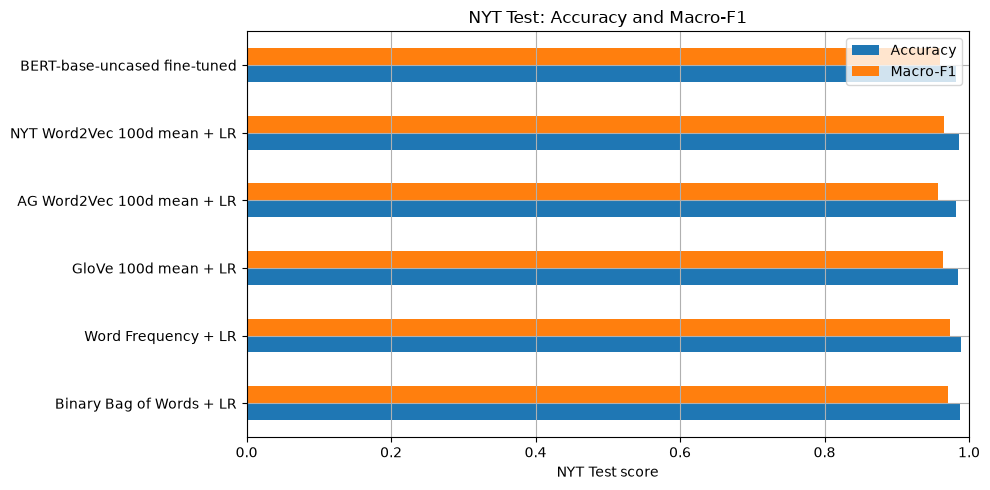

In [15]:
result_table = pd.DataFrame(results)
expected_methods = [
    "Binary Bag of Words + LR", "Word Frequency + LR", "GloVe 100d mean + LR",
    "AG Word2Vec 100d mean + LR", "NYT Word2Vec 100d mean + LR",
    "BERT-base-uncased fine-tuned",
]
if result_table["Method"].tolist() != expected_methods:
    raise RuntimeError("结果不完整，请从头运行所有实验单元。")
display(result_table.style.format({"Accuracy": "{:.4f}", "Macro-F1": "{:.4f}"}))
result_table.to_csv(ARTIFACT_DIR / "nyt_test_results.csv", index=False, encoding="utf-8-sig")

ax = result_table.set_index("Method")[["Accuracy", "Macro-F1"]].plot.barh(
    figsize=(10, 5), xlim=(0, 1), grid=True
)
ax.set_xlabel("NYT Test score")
ax.set_ylabel("")
ax.set_title("NYT Test: Accuracy and Macro-F1")
plt.tight_layout()
plt.show()

测试集 Macro-F1 最高：Word Frequency + LR，0.9743
Accuracy 与 Macro-F1 的差距：


,Method,Gap
0,Binary Bag of Words + LR,0.017488
1,Word Frequency + LR,0.015312
2,GloVe 100d mean + LR,0.020597
3,AG Word2Vec 100d mean + LR,0.025961
4,NYT Word2Vec 100d mean + LR,0.020315
5,BERT-base-uncased fine-tuned,0.022127


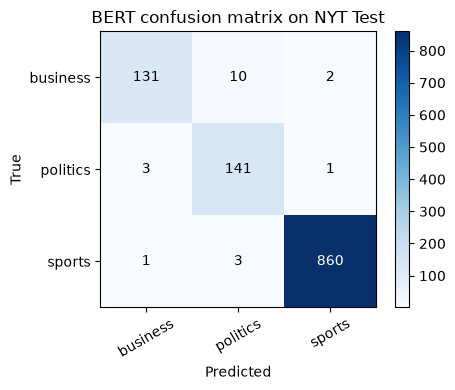

In [16]:
best_row = result_table.loc[result_table["Macro-F1"].idxmax()]
print(f"测试集 Macro-F1 最高：{best_row['Method']}，{best_row['Macro-F1']:.4f}")
print("Accuracy 与 Macro-F1 的差距：")
display(result_table.assign(Gap=result_table["Accuracy"] - result_table["Macro-F1"])[["Method", "Gap"]])

fig, ax = plt.subplots(figsize=(5, 4))
cm = confusion_matrix(y_test, bert_pred, labels=np.arange(len(class_names)))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(class_names)), class_names, rotation=30)
ax.set_yticks(range(len(class_names)), class_names)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("BERT confusion matrix on NYT Test")
for i in range(len(class_names)):
    for j in range(len(class_names)):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

### 实验报告建议

PDF 报告可直接引用上面的实际运行结果，按以下顺序撰写：

1. **数据与划分**：NYT/AG 规模、类别分布、固定随机种子、80/10/10 分层随机划分；说明 NYT 的完全重复文本未去重。
2. **方法**：Binary 与 Frequency 的区别；三种 100 维词向量的来源与平均池化；BERT 的模型、最大长度 64、3 epochs 和验证集 checkpoint 选择。
3. **结果**：放入六行测试集 Accuracy、Macro-F1 表格，以及必要的类别 F1 或混淆矩阵。
4. **分析**：根据真实结果比较词袋、GloVe、AG/NYT Word2Vec 和 BERT。结合词覆盖率、类别不均衡与 64 token 截断解释现象，不要预设某方法必然最好。
5. **复现信息**：Python/包版本、设备、训练耗时、随机种子、下载来源，以及从头运行命令。提交 PDF、Notebook、代码运行说明和 GitHub 链接。